# Inference for mixed models: likelihood-ratio tests, profiles and confidence intervals

How to test hypotheses and build confidence intervals for the parameters of a fitted mixed
model with lme4:

- **likelihood-ratio tests** (LRTs) between nested models with `anova()` — and why REML fits are
  refitted by maximum likelihood (ML) first — and single-term deletions with `drop1(test="Chisq")`
  or a user-supplied test (`test="user"`), plus a small parametric bootstrap of an LRT;
- **REML versus ML** estimates;
- **profile likelihood**: `profile()`, the profile zeta plots (`xyplot`), the implied densities
  (`densityplot`), the profile pairs plot (`splom`), and the `logProf()` / `varianceProf()`
  transformations;
- **confidence intervals** with `confint(method = "profile" | "Wald" | "boot")` and a comparison of
  the three;
- what lme4 says about **p-values** (`?pvalues`), for LMMs and GLMMs.

## Source

- lme4 help pages [`?anova.merMod`](https://github.com/lme4/lme4/blob/master/man/merMod-class.Rd),
  [`?drop1.merMod`](https://github.com/lme4/lme4/blob/master/man/drop1.merMod.Rd),
  [`?profile-methods`](https://github.com/lme4/lme4/blob/master/man/profile-methods.Rd),
  [`?plots.thpr`](https://github.com/lme4/lme4/blob/master/man/plots.thpr.Rd) (`xyplot`,
  `densityplot`, `splom` methods),
  [`?confint.merMod`](https://github.com/lme4/lme4/blob/master/man/confint.merMod.Rd) and
  [`?pvalues`](https://github.com/lme4/lme4/blob/master/man/pvalues.Rd); lme4's tests
  [`tests/profile-tst.R`](https://github.com/lme4/lme4/blob/master/tests/profile-tst.R) and
  [`tests/confint.R`](https://github.com/lme4/lme4/blob/master/tests/confint.R).
- Bates, Mächler, Bolker & Walker (2015), *Fitting Linear Mixed-Effects Models Using lme4*,
  J. Stat. Softw. 67(1), §5.1–5.2 (likelihood-ratio tests, profiling, `confint`, and the
  profile zeta / pairs plots), [doi:10.18637/jss.v067.i01](https://doi.org/10.18637/jss.v067.i01).
- The plotting methods are transcribed from `lme4/R/profile.R` (`xyplot.thpr`, `dens()`,
  `densityplot.thpr`, `splom.thpr`, `cont()`) into `lme4.plots_profile`, with matplotlib in place
  of lattice.

The R code (examples from the help pages; the complete reference script is
[`r/07_inference_profiles_and_tests.R`](r/07_inference_profiles_and_tests.R)):

```r
library(lme4)
## likelihood-ratio tests (?anova.merMod, ?drop1.merMod)
fm1 <- lmer(Reaction ~ Days + (Days | Subject), sleepstudy)
fm2 <- lmer(Reaction ~ Days + (Days || Subject), sleepstudy)
fm0 <- lmer(Reaction ~ 1 + (Days | Subject), sleepstudy)
anova(fm0, fm1)                    # refits with ML
anova(fm2, fm1)
anova(fm2, fm1, refit = FALSE)     # compares the REML criteria
drop1(fm1, test = "Chisq")
drop1(fm1, test = "user", sumFun = LRTSumFun)

## profiles (?profile-methods)
fm01ML <- lmer(Yield ~ 1|Batch, Dyestuff, REML = FALSE)
tpr  <- profile(fm01ML, optimizer = "Nelder_Mead", which = "beta_")
tpr  <- profile(fm01ML, signames = FALSE)
(confint(tpr) -> CIpr)
library(lattice)
xyplot(tpr)
xyplot(tpr, absVal = TRUE)
xyplot(tpr, conf = c(0.95, 0.99), main = "95% and 99% profile() intervals")
xyplot(logProf(tpr, ranef = FALSE), main = expression("lmer profile()s"~~ log(sigma)*" (only log)"))
densityplot(tpr, main = "densityplot( profile(lmer(..)) )")
densityplot(varianceProf(tpr), main = " varianceProf( profile(lmer(..)) )")
splom(tpr)
splom(logProf(tpr, ranef = FALSE))

## confidence intervals (?confint.merMod)
confint(fm1, method = "Wald")
confint(fm1)                       # method = "profile"
set.seed(123)
confint(fm1, method = "boot")
confint(fm2, maxpts = 8)

## GLMM
gm1 <- glmer(cbind(incidence, size - incidence) ~ period + (1 | herd), cbpp, family = binomial)
confint(gm1)
```

In [1]:
import contextlib
import io
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.testing import assert_allclose
from scipy import stats

import lme4
from lme4 import lmer, glmer, binomial, load_dataset, refitML
from lme4.plots_profile import dens, xyplot_thpr_data, splom_traces

%matplotlib inline
ref = json.load(open("reference/07_inference_profiles_and_tests.json", encoding="utf-8"))
print("R", ref["R_version"], "/ lme4", ref["lme4_version"], "  vs  lme4 for Python", lme4.__version__)


def num(v):
    """JSON from R: "NA" -> nan, scalars -> 1-element arrays"""
    v = v if isinstance(v, list) else [v]
    return np.array([np.nan if x == "NA" else x for x in v], float)


def check_ci(ci, r, rtol=1e-3):
    """compare a confint() table with ci_tab() from the R script"""
    rn = r["rownames"] if isinstance(r["rownames"], list) else [r["rownames"]]
    assert list(ci.index) == rn, (list(ci.index), rn)
    assert_allclose(ci.iloc[:, 0].values, num(r["lower"]), rtol=rtol)
    assert_allclose(ci.iloc[:, 1].values, num(r["upper"]), rtol=rtol)


def check_anova(tab, r, rtol=1e-5):
    assert_allclose(tab["npar"], num(r["npar"]))
    for col, key in [("AIC", "AIC"), ("BIC", "BIC"), ("logLik", "logLik"), ("-2*log(L)", "deviance"),
                     ("Chisq", "Chisq"), ("Df", "Df"), ("Pr(>Chisq)", "p")]:
        assert_allclose(tab[col].values, num(r[key]), rtol=rtol, equal_nan=True, err_msg=col)


pd.set_option("display.width", 120)
pd.set_option("display.precision", 6)

R 4.6.2 / lme4 2.1.0   vs  lme4 for Python 2.1.0a2


## 1. Likelihood-ratio tests with `anova()`

Three fits of the `sleepstudy` data (reaction time over 10 days of sleep deprivation, 18
subjects): the full model `fm1` with correlated random intercepts and slopes; `fm2`, the same
model with *uncorrelated* random effects (`||`); and `fm0`, which drops the fixed effect of `Days`.
All three are REML fits (lme4's default).

In [2]:
sleepstudy = load_dataset("sleepstudy")
fm1 = lmer("Reaction ~ Days + (Days | Subject)", sleepstudy)
fm2 = lmer("Reaction ~ Days + (Days || Subject)", sleepstudy)
fm0 = lmer("Reaction ~ 1 + (Days | Subject)", sleepstudy)
print(fm1.summary())

Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + (Days | Subject)
   Data: sleepstudy

REML criterion at convergence: 1743.6

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9536 -0.4634  0.0231  0.4634  5.1793 

Random effects:
 Groups   Name        Variance Std.Dev. Corr 
 Subject  (Intercept) 612.10   24.741        
          Days         35.07    5.922   0.07 
 Residual             654.94   25.592        
Number of obs: 180, groups:  Subject, 18

Fixed effects:
            Estimate Std. Error t value
(Intercept)  251.405      6.825  36.838
Days          10.467      1.546   6.771

Correlation of Fixed Effects:
     (Intr)
Days -0.138


**Testing a fixed effect.** The REML criterion depends on the fixed-effects model matrix (it is
the likelihood of a linear transformation of the data that removes the fixed effects), so REML
criteria of models with *different fixed effects* are not comparable. `anova()` therefore refits
REML models by maximum likelihood before computing the LRT statistic
$\chi^2 = 2(\ell_1 - \ell_0)$, referred to a $\chi^2$ distribution with the difference in the
number of parameters as degrees of freedom:

In [3]:
a_fixed = lme4.anova(fm0, fm1, model_names=["fm0", "fm1"])
a_fixed

refitting model(s) with ML (instead of REML)


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm0,5,1785.475882,1801.440666,-887.737941,1775.475882,NaN,NaN,NaN
fm1,6,1763.939344,1783.097086,-875.969672,1751.939344,23.536537,1.0,0.000001


**Testing a covariance parameter.** `fm2` and `fm1` differ only in the correlation of the random
intercept and slope. With the same fixed effects the REML criteria *are* comparable, so the test
can be done either way: by ML (default) or on the REML fits with `refit=False`.

In [4]:
a_corr = lme4.anova(fm2, fm1, model_names=["fm2", "fm1"])
a_corr_reml = lme4.anova(fm2, fm1, refit=False, model_names=["fm2", "fm1"])
display(a_corr)
a_corr_reml

refitting model(s) with ML (instead of REML)


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm2,5,1762.003255,1777.968039,-876.001628,1752.003255,NaN,NaN,NaN
fm1,6,1763.939344,1783.097086,-875.969672,1751.939344,0.063911,1.0,0.800418


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm2,5,1753.669294,1769.634078,-871.834647,1743.669294,NaN,NaN,NaN
fm1,6,1755.628272,1774.786013,-871.814136,1743.628272,0.041022,1.0,0.839496


There is no evidence of a correlation (p ≈ 0.8 either way). Note that the $\chi^2$ reference
distribution is an asymptotic approximation. For a test of a *variance* being zero (rather than a
correlation) the null value lies on the boundary of the parameter space, and the nominal
$\chi^2_1$ p-value is conservative (roughly twice too large); `?pvalues` points to simulation-based
tests (the `RLRsim` and `pbkrtest` packages) for such cases.

### Check against R

In [5]:
check_anova(a_fixed, ref["anova_fixed"])
check_anova(a_corr, ref["anova_corr"])
check_anova(a_corr_reml, ref["anova_corr_REML"])
print("ok")

ok


## 2. Single-term deletions: `drop1()`

`drop1()` refits the model without each fixed-effect term that can be dropped while respecting
marginality, again by ML, and reports AIC and (with `test="Chisq"`) the LRT:

In [6]:
d1 = fm1.drop1(test="Chisq")
d1

,npar,AIC,LRT,Pr(Chi)
<none>,NaN,1763.939344,NaN,NaN
Days,1.0,1785.475882,23.536537,0.000001


With `test="user"`, `drop1()` calls a summary function `sumFun(object, objectDrop, ...)` for each
reduced model; in R this is how Kenward–Roger or parametric-bootstrap tests from `pbkrtest` are
plugged in (see `?drop1.merMod`). Called without `objectDrop` it must return a vector of the right
length and names. Here, a function that returns the LRT from `anova()`:

In [7]:
def LRTSumFun(obj, objectDrop=None, **kw):
    nms = ["Chisq", "Df", "p.value"]
    if objectDrop is None:
        return pd.Series(np.nan, index=nms)
    a = lme4.anova(objectDrop, obj)
    return pd.Series([a["Chisq"].iloc[1], a["Df"].iloc[1], a["Pr(>Chisq)"].iloc[1]], index=nms)


du = fm1.drop1(test="user", sumFun=LRTSumFun)
du

refitting model(s) with ML (instead of REML)


,Chisq,Df,p.value
<none>,NaN,NaN,NaN
Days,23.536537,1.0,0.000001


### A parametric bootstrap of the LRT

The $\chi^2$ approximation can be checked by simulation: simulate responses from the fitted
*null* model `fm0` (ML), refit both models to each simulated response, and compare the observed
statistic with the simulated ones. (`pbkrtest::PBmodcomp` automates this in R.)

In [8]:
fm1ML = refitML(fm1)
fm0ML = refitML(fm0)
lrt_obs = 2 * (float(fm1ML.logLik()) - float(fm0ML.logLik()))
nsim_pb = 200
t0 = time.time()
ysim = fm0ML.simulate(nsim_pb, seed=101)
with contextlib.redirect_stderr(io.StringIO()):     # silence "boundary (singular) fit" messages
    lrt_sim = np.array([2 * (float(fm1ML.refit(ysim.iloc[:, k]).logLik())
                             - float(fm0ML.refit(ysim.iloc[:, k]).logLik()))
                        for k in range(nsim_pb)])
p_pb = (np.sum(lrt_sim >= lrt_obs) + 1) / (nsim_pb + 1)
print(f"observed LRT = {lrt_obs:.3f}; {nsim_pb} simulations in {time.time() - t0:.1f} s")
print(f"simulated LRT: mean {lrt_sim.mean():.3f} (chi^2_1: 1), 95% quantile "
      f"{np.quantile(lrt_sim, 0.95):.3f} (chi^2_1: {stats.chi2.ppf(0.95, 1):.3f})")
print(f"parametric bootstrap p-value = {p_pb:.4f}")

observed LRT = 23.537; 200 simulations in 2.5 s
simulated LRT: mean 0.916 (chi^2_1: 1), 95% quantile 3.267 (chi^2_1: 3.841)
parametric bootstrap p-value = 0.0050


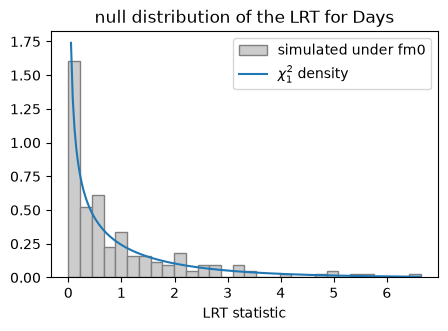

In [9]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(lrt_sim, bins=30, density=True, color="0.8", edgecolor="0.5", label="simulated under fm0")
xx = np.linspace(0.05, max(lrt_sim.max(), 6), 200)
ax.plot(xx, stats.chi2.pdf(xx, 1), color="C0", label=r"$\chi^2_1$ density")
ax.set_xlabel("LRT statistic"); ax.legend(); ax.set_title("null distribution of the LRT for Days")
plt.show()

The observed statistic (≈ 23.5) is far beyond every simulated value, so the bootstrap p-value is
the smallest possible, 1/(nsim + 1).

### Check against R

`drop1` statistics match R to `rtol=1e-5`. The parametric bootstrap draws different random
numbers than R (numpy's generator instead of R's Mersenne Twister/inversion), so only its
*conclusions* are compared: the same observed statistic, both p-values equal to 1/(nsim+1), and the
simulated null distributions loosely $\chi^2_1$-like (mean ≈ 1, 95 % quantile ≈ 3.8; with 200
simulations the sample 95 % quantile itself varies by ±1 or more).

In [10]:
r = ref["drop1"]
assert list(d1.index) == r["rownames"]
assert_allclose(d1["npar"], num(r["npar"]), equal_nan=True)
assert_allclose(d1["AIC"], num(r["AIC"]), rtol=1e-8)
assert_allclose(d1["LRT"], num(r["LRT"]), rtol=1e-5, equal_nan=True)
assert_allclose(d1["Pr(Chi)"], num(r["p"]), rtol=1e-5, equal_nan=True)
r = ref["drop1_user"]
assert list(du.index) == r["rownames"]
assert_allclose(du["Chisq"], num(r["Chisq"]), rtol=1e-5, equal_nan=True)
assert_allclose(du["p.value"], num(r["p"]), rtol=1e-5, equal_nan=True)
r = ref["pb_lrt"]
assert_allclose(lrt_obs, r["obs"], rtol=1e-6)
assert_allclose([p_pb, r["p"]], 1 / (nsim_pb + 1), rtol=1e-12)
for mean_, q95_ in [(lrt_sim.mean(), np.quantile(lrt_sim, 0.95)), (r["sim_mean"], r["sim_q95"])]:
    assert abs(mean_ - 1) < 0.5 and 2 < q95_ < 7     # loosely chi^2_1-like, far below 23.5
print("R:      mean", round(r["sim_mean"], 3), " q95", round(r["sim_q95"], 3))
print("Python: mean", round(lrt_sim.mean(), 3), " q95", round(np.quantile(lrt_sim, 0.95), 3))

R:      mean 1.272  q95 5.335
Python: mean 0.916  q95 3.267


## 3. REML versus ML

ML estimates of variance components are biased downwards because they ignore the degrees of
freedom used by the fixed effects; REML corrects for this (for a balanced design like this one
the fixed effects are identical). Use REML for reporting variance components, ML (via `anova()`'s
automatic refit) for comparing models with different fixed effects.

In [11]:
def vcrow(m):
    vc = m.VarCorr().as_data_frame()
    return pd.Series(list(vc["sdcor"]) + list(m.fixef()) + list(np.sqrt(np.diag(m.vcov().values))),
                     index=["sd(Intercept)", "sd(Days)", "corr", "sigma", "(Intercept)", "Days",
                            "se(Intercept)", "se(Days)"])


cmp = pd.DataFrame({"REML": vcrow(fm1), "ML": vcrow(fm1ML)})
cmp["ML/REML"] = cmp["ML"] / cmp["REML"]
print("REML criterion:", round(fm1.REMLcrit(), 4), "   ML deviance:", round(fm1ML.deviance(), 4))
cmp

REML criterion: 1743.6283    ML deviance: 1751.9393


,REML,ML,ML/REML
sd(Intercept),24.740658,23.780577,0.961194
sd(Days),5.922138,5.716836,0.965333
corr,0.065551,0.081320,1.240558
sigma,25.591796,25.591814,1.000001
(Intercept),251.405105,251.405105,1.000000
Days,10.467286,10.467286,1.000000
se(Intercept),6.824597,6.632279,0.971820
se(Days),1.545790,1.502237,0.971825


In [12]:
for m, key in [(fm1, "fm1_REML"), (fm1ML, "fm1_ML")]:
    r = ref[key]
    assert_allclose(m.VarCorr().as_data_frame()["sdcor"], r["sdcor"], rtol=1e-5)
    assert_allclose(m.fixef().values, r["fixef"], rtol=1e-7)
    assert_allclose(np.sqrt(np.diag(m.vcov().values)), r["se"], rtol=1e-5)
    assert_allclose(float(m.logLik()), r["logLik"], rtol=1e-9)
assert_allclose(fm1.REMLcrit(), ref["fm1_REML"]["REMLcrit"], rtol=1e-9)
assert_allclose(fm1ML.deviance(), ref["fm1_ML"]["deviance"], rtol=1e-9)
print("ok")

ok


## 4. Profiling the likelihood: `Dyestuff`

`profile()` evaluates, for each parameter in turn, the *profiled deviance*: the parameter is
held fixed at a sequence of values and the deviance is minimized over all the others. The result
is expressed as the signed square root
$$\zeta(\theta_i) = \operatorname{sign}(\theta_i - \hat\theta_i)\sqrt{d(\theta_i) - d(\hat\theta)},$$
which is a straight line if the log-likelihood is quadratic in that parameter (the situation in
which Wald intervals are accurate). Profile intervals are the parameter values where $|\zeta|$
reaches $\sqrt{\chi^2_{1}(\text{level})}$ (1.96 for 95 %). Example from `?profile-methods`: the
yield of dyestuff in 6 batches, fitted by ML.

Only the fixed effect, with the Nelder–Mead optimizer:

In [13]:
Dyestuff = load_dataset("Dyestuff")
fm01ML = lmer("Yield ~ 1|Batch", Dyestuff, REML=False)
t0 = time.time()
tprb = fm01ML.profile(optimizer="Nelder_Mead", which="beta_")
print(f"{time.time() - t0:.2f} s")
tprb.confint()

0.03 s


,2.5 %,97.5 %
(Intercept),1486.4515,1568.548494


All parameters, labelled by the names used in `VarCorr` (`signames=False`) rather than
`.sig01`/`.sigma`:

In [14]:
t0 = time.time()
tpr = fm01ML.profile(signames=False)
print(f"{time.time() - t0:.2f} s")
CIpr = tpr.confint()
CIpr

0.12 s


,2.5 %,97.5 %
sd_(Intercept)|Batch,12.198535,84.063047
sigma,38.229985,67.657696
(Intercept),1486.451500,1568.548494


In [15]:
tpr.as_data_frame().head(8)       # the profile: one block of rows per parameter

,.zeta,sd_(Intercept)|Batch,sigma,(Intercept),.par,.focal
0,-2.324398,0.000000,61.964371,1527.5,sd_(Intercept)|Batch,0.000000
1,-2.227002,6.315427,60.742948,1527.5,sd_(Intercept)|Batch,6.315427
2,-1.952750,12.317274,57.713549,1527.5,sd_(Intercept)|Batch,12.317274
3,-1.598594,17.365855,54.699725,1527.5,sd_(Intercept)|Batch,17.365855
4,-1.187273,22.298052,52.321453,1527.5,sd_(Intercept)|Batch,22.298052
5,-0.732599,27.624412,50.725595,1527.5,sd_(Intercept)|Batch,27.624412
6,-0.265446,33.534311,49.814211,1527.5,sd_(Intercept)|Batch,33.534311
7,0.000000,37.260345,49.510100,1527.5,sd_(Intercept)|Batch,37.260345


### Profile zeta plots (`xyplot`)

The vertical lines mark the 50, 80, 90, 95 and 99 % profile intervals. The profile of the batch
standard deviation is strongly curved and its 99 % lower limit is 0 (the profile does not reach
$|\zeta| = 2.58$ before $\sigma_1 = 0$); the residual standard deviation is skewed to the right; the
intercept is close to linear.

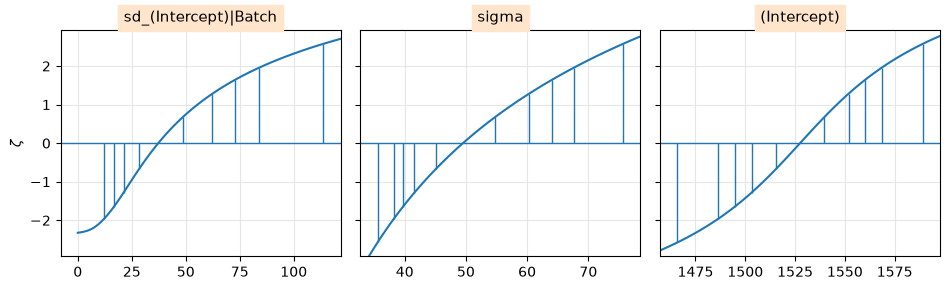

In [16]:
tpr.xyplot();

With `absVal=True` the plot of $|\zeta|$ makes the (a)symmetry of the intervals easier to see;
`conf` chooses the confidence levels shown:

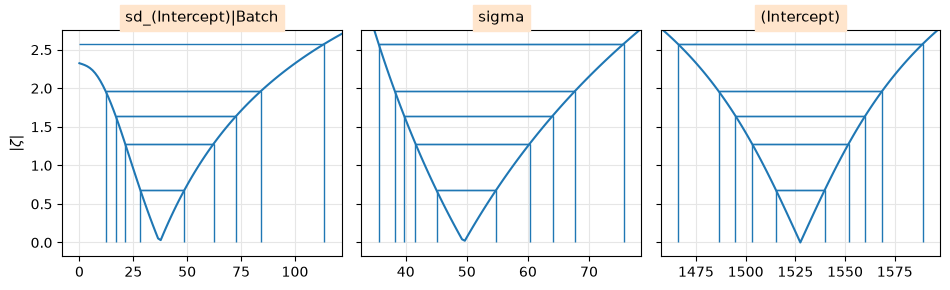

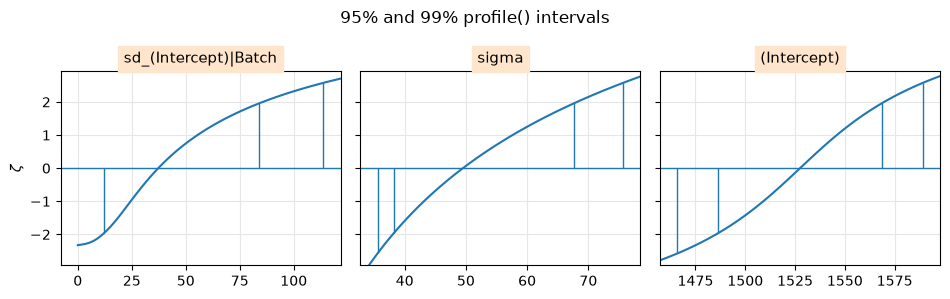

In [17]:
tpr.xyplot(absVal=True);
tpr.xyplot(conf=[0.95, 0.99], main="95% and 99% profile() intervals");

### `logProf()` and `varianceProf()`

`logProf()` converts the standard deviations `.sigNN` (and, with `ranef=True`, also `.sigma`)
to the log scale, `varianceProf()` to variances; the splines are recomputed and `confint()` works
on the new scale. These functions recognise the parameters by their default names (`.sig01`,
`.sigma`), so they leave a profile computed with `signames=False` unchanged — the R example
`logProf(tpr, ranef=FALSE)` on such a profile is a no-op. We therefore profile again with the
default names:

In [18]:
assert list(tpr.logProf(ranef=False).columns) == list(tpr.columns)   # unchanged, as in R
tprS = fm01ML.profile()
lp = tprS.logProf(ranef=False)       # only sigma on the log scale
lp2 = tprS.logProf()                 # sigma_1 and sigma
vp = tprS.varianceProf()
pd.concat({"sd": tprS.confint(), "log(sigma) only": lp.confint(), "log": lp2.confint(),
           "variance": vp.confint()}, axis=1)

sd              log(sigma) only                       log                  variance             
                   2.5 %       97.5 %           2.5 %       97.5 %        2.5 %       97.5 %        2.5 %       97.5 %
.sig01         12.198535    84.063047       12.198535    84.063047          NaN          NaN          NaN          NaN
.sigma         38.229985    67.657696             NaN          NaN          NaN          NaN          NaN          NaN
(Intercept)  1486.451500  1568.548494     1486.451500  1568.548494  1486.451500  1568.548494  1486.451500  1568.548494
.lsigma              NaN          NaN        3.643623     4.214461     3.643623     4.214461          NaN          NaN
.lsig01              NaN          NaN             NaN          NaN     2.500998     4.431571          NaN          NaN
.sigsq01             NaN          NaN             NaN          NaN          NaN          NaN   148.755095  7066.290437
.sigmasq             NaN          NaN             NaN          NaN          NaN          NaN  1461.519723  4577.562333

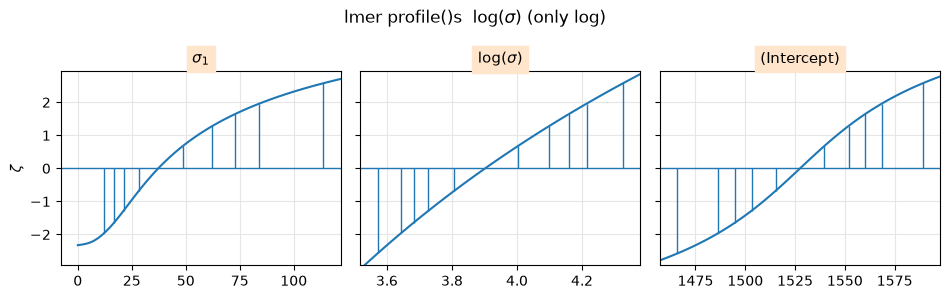

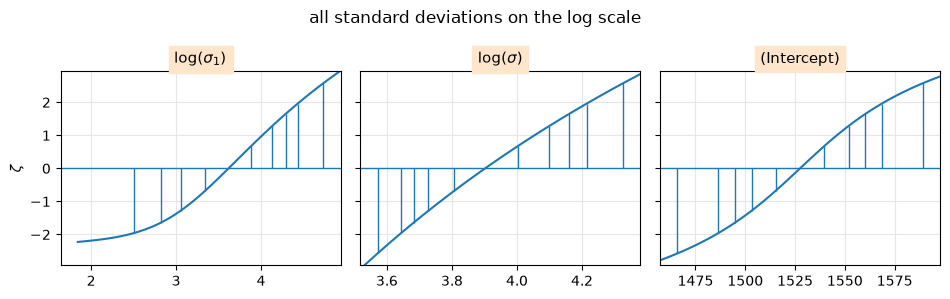

In [19]:
lp.xyplot(main=r"lmer profile()s  $\log(\sigma)$ (only log)");
lp2.xyplot(main="all standard deviations on the log scale");

On the log scale the profiles are much closer to straight lines: the log of a standard deviation
is a better scale for a quadratic (Wald-type) approximation than the standard deviation itself,
and the variance is the worst.

### Densities implied by the profile (`densityplot`)

Interpreting $\zeta$ as a standard normal variable gives a density for each parameter,
$\phi(\zeta(\theta))\,\zeta'(\theta)$ — the shape a posterior distribution would have under a flat
prior and a normal likelihood approximation on the $\zeta$ scale.

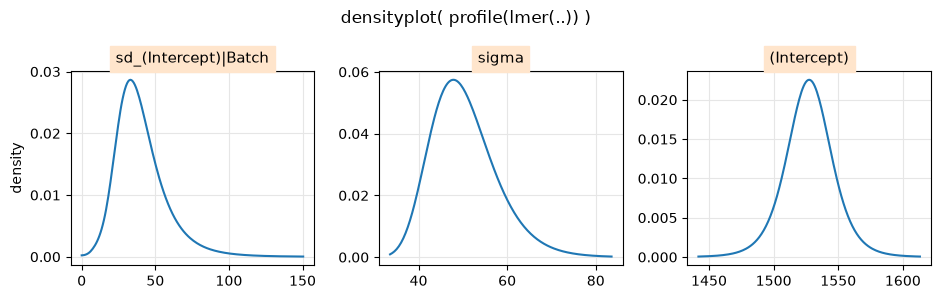

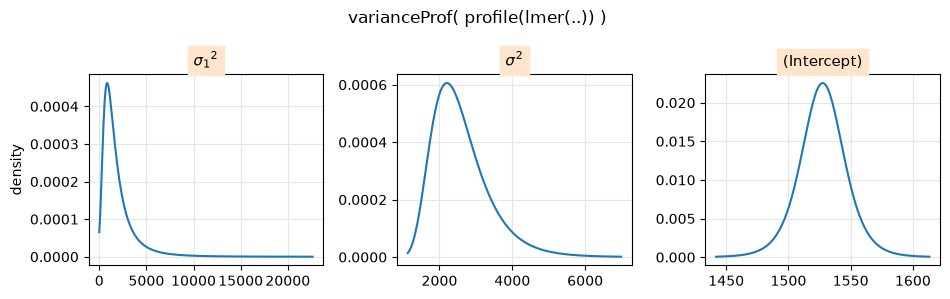

In [20]:
tpr.densityplot(main="densityplot( profile(lmer(..)) )");
vp.densityplot(main=" varianceProf( profile(lmer(..)) )");

### Profile pairs plot (`splom`)

Below the diagonal, on the $\zeta$ scale: the *profile traces* (the conditional estimate of one
parameter given the other, the two lines) and the contours of the 2-d profile regions for
50–99 % (with $\chi^2_2$ quantiles). Above the diagonal the same on the original scale. Straight,
orthogonal traces and elliptical contours would indicate a quadratic log-likelihood. The contours
for $\sigma_1$ are cut off at $\sigma_1 = 0$.

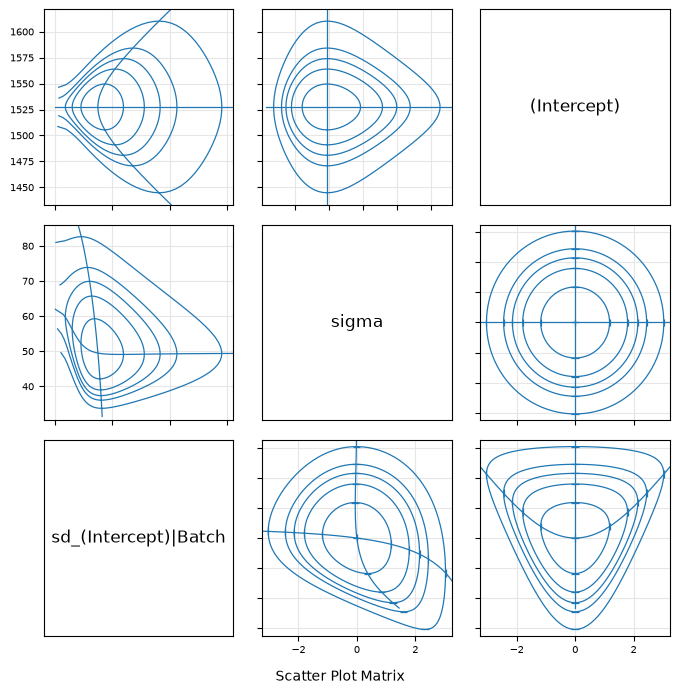

In [21]:
tpr.splom();

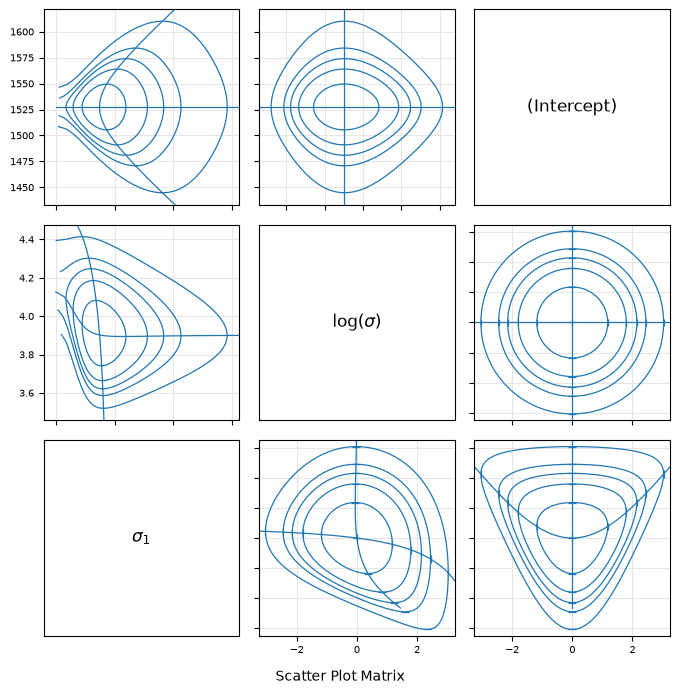

In [22]:
lp.splom();

### REML versus ML profiles

`profile()` always works with the ML deviance: its `devfun2()` begins with `refitML()`. The
profile intervals of a REML fit are therefore identical to those of the corresponding ML fit,
even though the REML point estimates differ (σ₁ = 42.0 by REML versus 37.3 by ML here):

In [23]:
fm01 = lmer("Yield ~ 1|Batch", Dyestuff)
ci_reml = fm01.confint()
pd.concat({"ML": tprS.confint(), "REML": ci_reml}, axis=1)

Computing profile confidence intervals ...


ML                      REML             
                   2.5 %       97.5 %        2.5 %       97.5 %
.sig01         12.198535    84.063047    12.198535    84.063047
.sigma         38.229985    67.657696    38.229985    67.657696
(Intercept)  1486.451500  1568.548494  1486.451500  1568.548494

### Check against R

The profile intervals agree with R's to ~1e-9. Beyond the intervals, the *data* drawn in each
plot are compared with R: the parameter values at the $\zeta$ levels of `xyplot`, the
density grid of `dens()`, and, for `splom`, the parameter ranges and the contour points of all
three pairs produced by `cont()` (including the periodic-spline interpolation).

In [24]:
check_ci(tprb.confint(), ref["dyestuff_beta_ci"], rtol=1e-6)
check_ci(CIpr, ref["dyestuff_ci"], rtol=1e-6)
check_ci(tpr.confint(level=0.90), ref["dyestuff_ci_90"], rtol=1e-6)
check_ci(tprS.confint(), ref["dyestuff_ciS"], rtol=1e-6)
check_ci(vp.confint(), ref["dyestuff_var_ci"], rtol=1e-6)
check_ci(lp.confint(), ref["dyestuff_log_ci"], rtol=1e-6)
check_ci(lp2.confint(), ref["dyestuff_log2_ci"], rtol=1e-6)
check_ci(ci_reml, ref["dyestuff_REML_ci"], rtol=1e-6)
assert ref["dyestuff_logProf_unchanged"]

# xyplot: parameter values at the zeta levels (R gives NA where the profile does not reach)
fr, _ = xyplot_thpr_data(tpr)
for nm, v in ref["dyestuff_xyplot"]["pval"].items():
    v = num(v)
    got = fr.loc[fr["pnm"] == nm, "pval"].values
    ok = ~np.isnan(v)
    assert_allclose(got[ok], v[ok], rtol=1e-6)
    assert np.all(fr.loc[fr["pnm"] == nm, "zeta"].values[~ok] == 0)   # NA -> zeta 0 at min(knots)

# densityplot
for d, key in [(dens(tpr), "dyestuff_dens"), (dens(vp), "dyestuff_var_dens")]:
    r = ref[key]
    assert list(d["pnm"].astype(str)) == r["pnm"]
    assert_allclose(d["pval"], r["pval"], rtol=1e-6, atol=1e-10)
    assert_allclose(d["density"], r["density"], rtol=1e-4, atol=1e-6 * max(r["density"]))

# splom
tr = splom_traces(tpr)
s = ref["dyestuff_splom"]
assert_allclose(tr["pfr"].values[0], s["pfr_lower"], rtol=1e-6, atol=1e-10)
assert_allclose(tr["pfr"].values[1], s["pfr_upper"], rtol=1e-6)
for key, c in s["conts"].items():
    j, i = (int(a) - 1 for a in key.split("_"))
    ll = tr["traces"][(j, i)]["ll"]
    assert_allclose(ll["tki"][1], c["tki"], atol=1e-5)
    assert_allclose(ll["tkj"][1], c["tkj"], atol=1e-5)
    assert_allclose(ll["pts"][:, :, 0].ravel(order="F"), c["pts1"], atol=1e-5)
    assert_allclose(ll["pts"][:, :, 1].ravel(order="F"), c["pts2"], atol=1e-5)
print("ok")

ok


## 5. Three kinds of confidence intervals: `sleepstudy`

`confint()` offers three methods (`?confint.merMod`):

- `"Wald"`: $\hat\beta \pm z_{\alpha/2}\,\mathrm{SE}$ — instantaneous, but only for the fixed
  effects (the variance-component rows are `NA`) and relying on a quadratic log-likelihood;
- `"profile"` (default): inverts the likelihood-ratio test along the profile;
- `"boot"`: percentiles of a parametric bootstrap (`bootMer`), here with 500 simulations.

Parameters are named `.sig01` (sd of the intercept), `.sig02` (sd of the slope), `.sig03`
(their correlation), `.sigma` and the fixed effects (the plot labels σ₁, σ₂, σ₃ follow R's
`stripExpr()`, which labels every `.sigNN` as σ, the correlation included). The REML fit `fm1`
is used, as in the help page.

In [25]:
ci_wald = fm1.confint(method="Wald")
t0 = time.time()
pr1 = fm1.profile()
ci_prof = pr1.confint()
print(f"profile: {time.time() - t0:.1f} s")
t0 = time.time()
with warnings.catch_warnings(), contextlib.redirect_stderr(io.StringIO()):
    warnings.simplefilter("ignore")    # convergence warnings / singular fits of some samples
    ci_boot = fm1.confint(method="boot", nsim=500, seed=123)
print(f"bootstrap: {time.time() - t0:.1f} s")
ci_all = pd.concat({"Wald": ci_wald, "profile": ci_prof, "boot": ci_boot}, axis=1)
ci_all

profile: 2.4 s


bootstrap: 3.0 s


Wald                 profile                    boot            
                  2.5 %      97.5 %       2.5 %      97.5 %       2.5 %      97.5 %
.sig01              NaN         NaN   14.381403   37.715996   11.511404   35.343735
.sig02              NaN         NaN    3.801164    8.753383    3.299385    8.502519
.sig03              NaN         NaN   -0.481501    0.684986   -0.483632    0.989260
.sigma              NaN         NaN   22.898267   28.857997   22.422434   28.489222
(Intercept)  238.029141  264.781069  237.680696  265.129515  238.873001  266.112755
Days           7.437594   13.496978    7.358653   13.575919    7.486673   13.402997

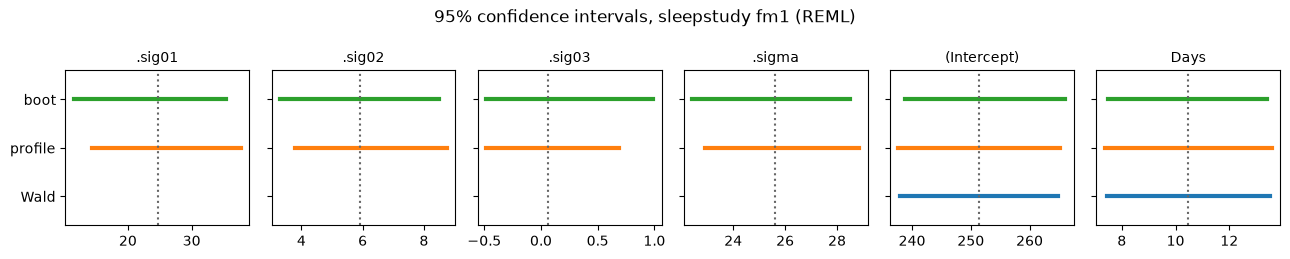

In [26]:
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
est = pd.Series(list(fm1.VarCorr().as_data_frame()["sdcor"]) + list(fm1.fixef()), index=ci_prof.index)
for ax, nm in zip(axes, ci_prof.index):
    for k, (meth, ci) in enumerate([("Wald", ci_wald), ("profile", ci_prof), ("boot", ci_boot)]):
        lo, hi = ci.loc[nm]
        if np.isfinite(lo):
            ax.plot([lo, hi], [k, k], color=f"C{k}", lw=3)
    ax.axvline(est[nm], color="0.4", ls=":")
    ax.set_yticks(range(3)); ax.set_yticklabels(["Wald", "profile", "boot"] if nm == ".sig01" else [])
    ax.set_ylim(-0.6, 2.6); ax.set_title(nm, fontsize=10)
fig.suptitle("95% confidence intervals, sleepstudy fm1 (REML)"); fig.tight_layout()
plt.show()

For the fixed effects the three intervals nearly coincide. For the variance components the
profile and bootstrap intervals are asymmetric; the correlation interval is very wide (with 18
subjects it is poorly determined). The two are not computed from the same criterion: the profile
is based on the ML deviance (see §4), while the bootstrap simulates from the REML estimates and
refits each sample by REML; the percentile limits from 500 simulations also carry Monte Carlo
error.

The profile of `fm1`:

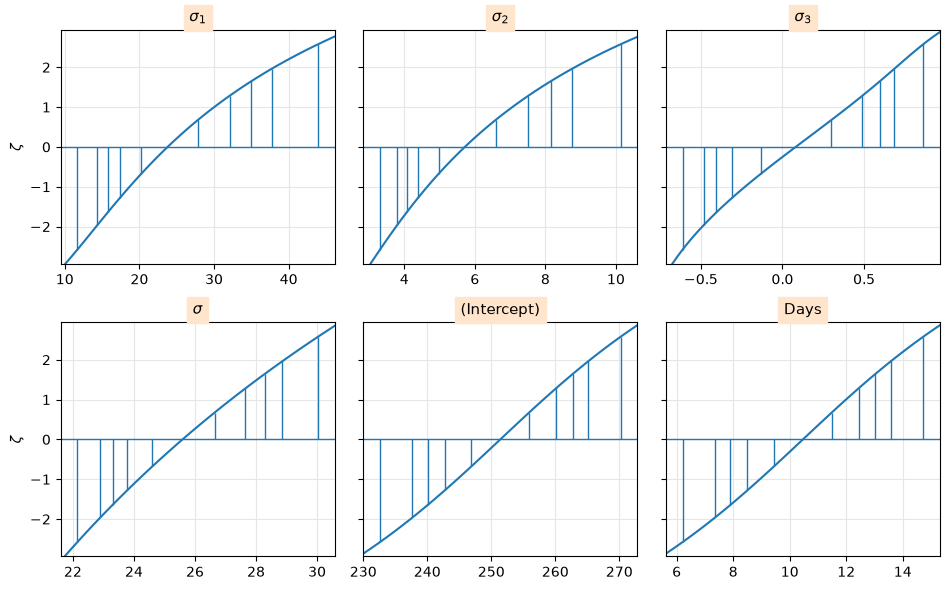

In [27]:
pr1.xyplot();

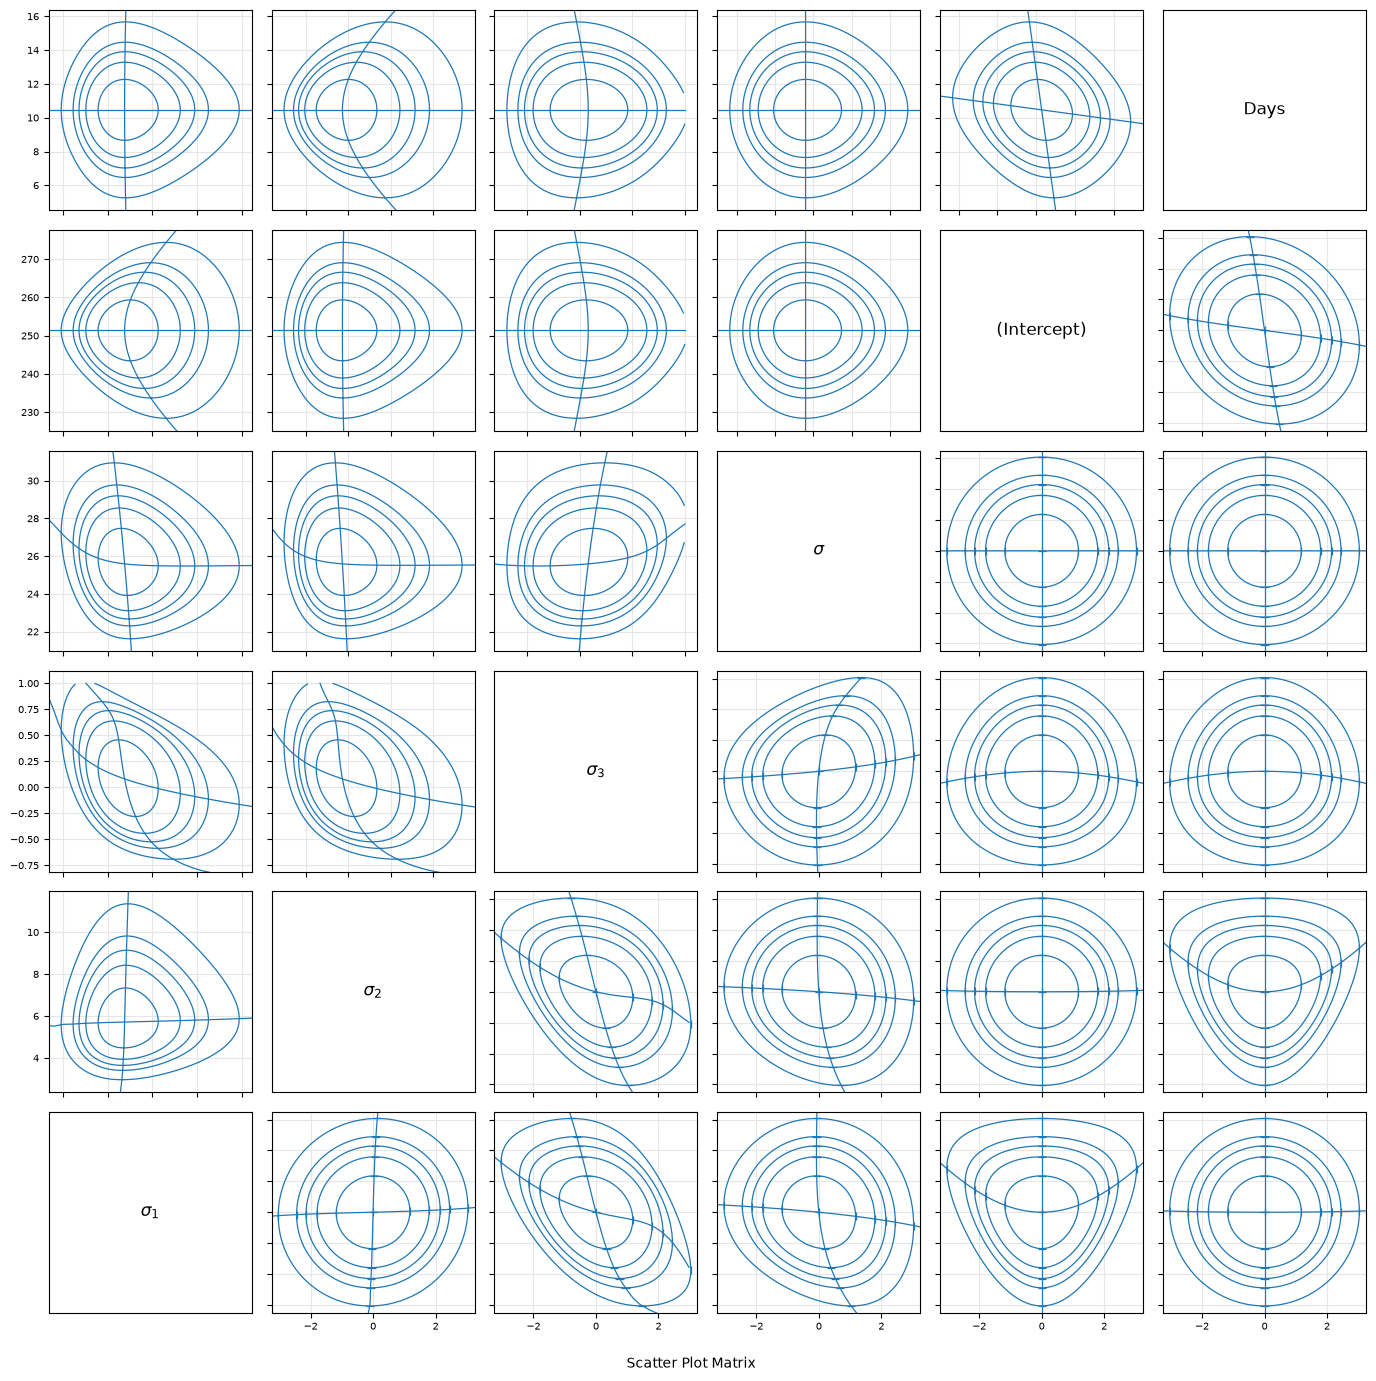

In [28]:
pr1.splom();

`maxpts` limits the number of profile points per direction, trading accuracy for speed (the
help page uses `maxpts = 8` for the uncorrelated model):

In [29]:
ci_fm2 = fm2.confint(maxpts=8)
ci_fm2

Computing profile confidence intervals ...


,2.5 %,97.5 %
.sig01,15.258466,37.781844
.sig02,3.964157,8.768238
.sigma,22.880622,28.787681
(Intercept),237.573221,265.238327
Days,7.334310,13.600565


### Check against R

Wald and profile intervals agree with R to `rtol=1e-3` or better. The bootstrap cannot reproduce
R's random numbers, so its intervals are compared loosely: each limit is within a tolerance
proportional to the width of the profile interval (25 % of it), which is roughly the Monte Carlo
error of a 2.5 % / 97.5 % percentile from 500 simulations.

In [30]:
check_ci(ci_wald.iloc[4:], {k: (v[4:] if isinstance(v, list) else v) for k, v in ref["fm1_wald"].items()},
         rtol=1e-6)
assert ci_wald.iloc[:4].isna().all().all() and ref["fm1_wald"]["lower"][:4] == ["NA"] * 4
check_ci(ci_prof, ref["fm1_profile_ci"], rtol=1e-3)
check_ci(ci_fm2, ref["fm2_ci_maxpts8"], rtol=1e-3)
# help-page target values for confint(fm2, maxpts = 8)
assert_allclose(ci_fm2.values.ravel(order="F"),
                [15.25847, 3.964157, 22.88062, 237.5732, 7.33431,
                 37.78184, 8.768238, 28.78768, 265.2383, 13.60057], rtol=5e-5)
rb = ref["fm1_boot_ci"]
assert list(ci_boot.index) == rb["rownames"]
width = (ci_prof.iloc[:, 1] - ci_prof.iloc[:, 0]).values
for col, key in [(0, "lower"), (1, "upper")]:
    diff = np.abs(ci_boot.iloc[:, col].values - num(rb[key]))
    print(key, "|Python - R| / profile width:", np.round(diff / width, 3))
    assert np.all(diff < 0.25 * width)
print("ok")

lower |Python - R| / profile width: [0.034 0.006 0.03  0.052 0.027 0.028]
upper |Python - R| / profile width: [0.023 0.083 0.092 0.035 0.007 0.01 ]
ok


## 6. A GLMM: `cbpp`

For generalized linear mixed models `summary()` reports Wald *z* tests with p-values ("standard
practice for generalized linear models", `?pvalues`, but relying on the shape of the
log-likelihood surface). Likelihood-ratio tests and profile intervals are also available (there is
no REML for GLMMs, so no refitting is involved):

In [31]:
cbpp = load_dataset("cbpp")
gm1 = glmer("cbind(incidence, size - incidence) ~ period + (1 | herd)", cbpp, family=binomial)
gm0 = glmer("cbind(incidence, size - incidence) ~ 1 + (1 | herd)", cbpp, family=binomial)
gm1.summary().coefficients

,Estimate,Std. Error,z value,Pr(>|z|)
(Intercept),-1.398532,0.232473,-6.015881,1.789108e-09
period2,-0.992316,0.306641,-3.236078,1.211841e-03
period3,-1.128664,0.326637,-3.455403,5.494708e-04
period4,-1.580316,0.427437,-3.697187,2.180021e-04


In [32]:
g_anova = lme4.anova(gm0, gm1, model_names=["gm0", "gm1"])
g_drop1 = gm1.drop1(test="Chisq")
display(g_anova)
g_drop1

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
gm0,2,213.662627,217.713331,-104.831314,209.662627,NaN,NaN,NaN
gm1,5,194.052564,204.179322,-92.026282,184.052564,25.610063,3.0,0.000012


,npar,AIC,LRT,Pr(Chi)
<none>,NaN,194.052564,NaN,NaN
period,3.0,213.662627,25.610063,0.000012


In [33]:
g_wald = gm1.confint(method="Wald")
t0 = time.time()
g_prof = gm1.confint()
print(f"profile: {time.time() - t0:.1f} s")
pd.concat({"Wald": g_wald, "profile": g_prof}, axis=1)

Computing profile confidence intervals ...


profile: 3.7 s


Wald             profile          
                2.5 %    97.5 %     2.5 %    97.5 %
.sig01            NaN       NaN  0.346092  1.099953
(Intercept) -1.854171 -0.942893 -1.901188 -0.947788
period2     -1.593322 -0.391310 -1.616767 -0.407780
period3     -1.768862 -0.488466 -1.801008 -0.511553
period4     -2.418077 -0.742554 -2.500759 -0.800757

The profile intervals of the `period` effects are slightly asymmetric and shifted relative to
the Wald intervals; `.sig01` (the herd standard deviation) has no Wald interval at all.

### Check against R

In [34]:
cf = gm1.summary().coefficients
assert_allclose(cf["z value"].values, ref["gm1_coef"]["z"], rtol=1e-4)
assert_allclose(cf["Pr(>|z|)"].values, ref["gm1_coef"]["p"], rtol=1e-3)
check_anova(g_anova, ref["gm1_anova"], rtol=1e-5)
r = ref["gm1_drop1"]
assert list(g_drop1.index) == r["rownames"]
assert_allclose(g_drop1["LRT"], num(r["LRT"]), rtol=1e-5, equal_nan=True)
assert_allclose(g_drop1["Pr(Chi)"], num(r["p"]), rtol=1e-5, equal_nan=True)
r = ref["gm1_wald_ci"]
check_ci(g_wald.iloc[1:], {"rownames": r["rownames"][1:], "lower": num(r["lower"])[1:].tolist(),
                           "upper": num(r["upper"])[1:].tolist()}, rtol=1e-4)
check_ci(g_prof, ref["gm1_profile_ci"], rtol=1e-3)
print("ok")

ok


## 7. What about p-values for the LMM coefficients?

`summary(fm1)` shows *t* values but no p-values. `?pvalues` explains why: the null distribution of
these statistics is not exactly a *t* distribution with known degrees of freedom, and lme4 does
not pick an approximation for the user. Its list of options (MC = model comparison, CI =
confidence interval, P = parameter-level tests; * = finite-size correction, important with fewer
than about 50 groups; + = also for GLMMs):

- likelihood-ratio tests via `anova` or `drop1` (MC, +) — §1–2 above;
- profile confidence intervals via `profile` and `confint` (CI, +) — §4–5;
- parametric bootstrap intervals and model comparisons via `bootMer` (or `PBmodcomp` in
  `pbkrtest`) (MC/CI, *, +) — §2 and §5;
- for random effects, simulation tests via the `RLRsim` package (MC, *);
- for fixed effects, Kenward–Roger F tests (`pbkrtest::KRmodcomp`) (MC, *);
- `car::Anova` and `lmerTest::anova` (Kenward–Roger; Satterthwaite *t* tests in `lmerTest`)
  (P, *); `afex::mixed` ("Type 3" tests) (P, *, +).

The Satterthwaite and Kenward–Roger approximations live in those *other* R packages, not in
lme4, and are out of scope here. `?pvalues` ends: "When all else fails, don't forget to keep
p-values in perspective."

For illustration only, the large-sample normal approximation to the *t* values (which ignores
the uncertainty in the variance components and is anti-conservative for small numbers of groups):

In [35]:
cf = fm1.summary().coefficients.copy()
cf["Pr(>|z|) (normal approx.)"] = 2 * stats.norm.sf(np.abs(cf["t value"]))
assert_allclose(cf["t value"].values, ref["fm1_coef"]["t"], rtol=1e-6)
cf

,Estimate,Std. Error,t value,Pr(>|z|) (normal approx.)
(Intercept),251.405105,6.824597,36.838090,4.537104e-297
Days,10.467286,1.545790,6.771481,1.274703e-11


## Summary

| question | tool | notes |
|---|---|---|
| compare nested models | `anova(m0, m1)` | REML fits refitted by ML; `refit=False` only for equal fixed effects |
| test each fixed term | `m.drop1(test="Chisq")` | ML refits; `test="user"` with `sumFun` for other tests |
| small-sample check of an LRT | `simulate` + `refit` (parametric bootstrap) | random numbers differ from R |
| intervals for β | `confint(method="Wald")`, `"profile"`, `"boot"` | nearly identical for LMM fixed effects |
| intervals for variance components | `confint()` (profile) or `"boot"` | Wald gives `NA`; profiles are asymmetric |
| shape of the likelihood | `profile()`, `.xyplot()`, `.densityplot()`, `.splom()` | `logProf()` often makes profiles straighter |

The plotting methods are in `lme4.plots_profile` (also available as `thpr.xyplot()`,
`thpr.densityplot()`, `thpr.splom()`); the numbers they draw match R's `xyplot.thpr`, `dens()` and
`splom.thpr` internals.